<a href="https://colab.research.google.com/github/kamcio-eng/podstawy-si-lab/blob/main/AI_lab2_gry.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Podstawy sztucznej inteligencji — Laboratorium 2
# Gry: jak komputer wybiera ruch

Ten notatnik jest przeznaczony do pracy w **Google Colab**. Uruchamiaj komórki **po kolei, od góry**.
Jeśli coś działa dziwnie: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*.

## Główny pomysł

Zanim komputer wykona ruch, **wyobraża sobie wszystkie możliwe dalsze przebiegi gry aż do końca**
i wybiera ruch, który jest najlepszy przy założeniu, że **przeciwnik też gra najlepiej, jak może**.

Notatnik rozwija ten pomysł w trzech krokach:

| sekcja | pytanie |
|---|---|
| 1. Gra jako dane | Jak opisać grę komputerowi? |
| 2. Minimax | Jak komputer „wyobraża sobie” przebieg gry? |
| 3. Alfa-beta | Jak zrobić to samo dużo szybciej? |

Nawiązanie do laboratorium 1: tam A* szukał drogi do celu w świecie, który się nie bronił.
Tu po drugiej stronie siedzi **przeciwnik**, który chce dokładnie odwrotnie niż my.

# 1. Gra jako dane

## 1.1. Plansza

Planszę kółka i krzyżyka zapisujemy jako **krotkę 9 znaków**. Pola numerujemy wiersz po wierszu:

```text
0 | 1 | 2
3 | 4 | 5
6 | 7 | 8
```

`'X'` i `'O'` to znaki graczy, `'.'` to wolne pole. Taką planszę nazywamy **stanem gry**:
to wszystko, co program wie o grze w danej chwili.

**Dlaczego krotka, a nie lista?** Krotki nie da się zmienić. Każdy ruch tworzy więc **nową** planszę,
a stara zostaje nietknięta. To będzie bardzo ważne w sekcji 2.

In [1]:
import math
import random
import time
import matplotlib.pyplot as plt

random.seed(0)

# Przykładowa plansza: X w dwóch rogach, O w środku
s = ('X', '.', '.',
     '.', 'O', '.',
     '.', '.', 'X')

print("Pole 0:", s[0])
print("Pole 4:", s[4])
print("Ile wolnych pól:", s.count('.'))

Pole 0: X
Pole 4: O
Ile wolnych pól: 6


## 1.2. Zasady gry w sześciu funkcjach

Komputer nie zna zasad kółka i krzyżyka. Uczymy go ich przez sześć funkcji:

| funkcja | pytanie, na które odpowiada | kółko i krzyżyk |
|---|---|---|
| `start` | jak wygląda plansza na początku? | 9 wolnych pól |
| `gracz(s)` | kto teraz rusza? | `"MAX"` (X) albo `"MIN"` (O) |
| `akcje(s)` | jakie ruchy są możliwe? | numery wolnych pól |
| `wynik(s, a)` | jak wygląda plansza po ruchu `a`? | nowa plansza z nowym znakiem |
| `koniec(s)` | czy gra się skończyła? | trzy w linii albo brak wolnych pól |
| `wyplata(s)` | kto wygrał? | +1, 0 albo −1 |

### Wypłata: zawsze z punktu widzenia X

- wygrał X → **+1**
- remis → **0**
- wygrał O → **−1**

Wystarczy jedna liczba: X chce, żeby była **jak największa**, a O, żeby była **jak najmniejsza**.
Dlatego gracza X nazywamy **MAX**, a gracza O nazywamy **MIN**.

Funkcje zbieramy w jednej klasie. Klasa to tu po prostu „paczka funkcji opisujących jedną grę”.

In [2]:
# Wszystkie 8 linii, w których można ułożyć trzy znaki
LINIE = [(0, 1, 2), (3, 4, 5), (6, 7, 8),   # wiersze
         (0, 3, 6), (1, 4, 7), (2, 5, 8),   # kolumny
         (0, 4, 8), (2, 4, 6)]              # przekątne


class KolkoKrzyzyk:

    start = ('.',) * 9          # 9 wolnych pól

    def gracz(self, s):
        if s.count('X') == s.count('O'):
            return "MAX"
        else:
            return "MIN"

    def akcje(self, s):
        wolne = []
        for i in range(9):
            if s[i] == '.':
                wolne.append(i)
        return wolne

    def wynik(self, s, a):
        if self.gracz(s) == "MAX":
            znak = 'X'
        else:
            znak = 'O'
        # nowa krotka: pola przed a, nowy znak, pola po a
        return s[:a] + (znak,) + s[a + 1:]

    def zwyciezca(self, s):
        for a, b, c in LINIE:
            if s[a] != '.' and s[a] == s[b] == s[c]:
                return s[a]          # 'X' albo 'O'
        return None                  # nikt nie wygrał

    def koniec(self, s):
        return self.zwyciezca(s) is not None or '.' not in s

    def wyplata(self, s):
        z = self.zwyciezca(s)
        if z == 'X':
            return 1
        if z == 'O':
            return -1
        return 0


kk = KolkoKrzyzyk()

### Sprawdźmy, jak działają te funkcje

Pomocnicza funkcja `z_napisu` pozwala zapisać planszę krócej: `"X...O...X"` zamiast krotki z 9 elementami.
Funkcja `rysuj` rysuje planszę. **Nie musisz rozumieć, jak działa** `rysuj` — to tylko obrazek.

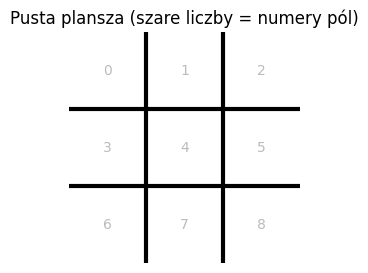

Kto rusza: MAX
Możliwe ruchy: [0, 1, 2, 3, 4, 5, 6, 7, 8]


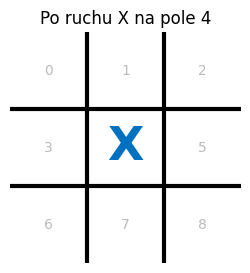

Kto rusza: MIN
Możliwe ruchy: [0, 1, 2, 3, 5, 6, 7, 8]


In [3]:
def z_napisu(napis):
    # 'X...O...X' -> ('X', '.', '.', '.', 'O', '.', '.', '.', 'X')
    return tuple(napis)


def rysuj(s, liczby=None, tytul=""):
    # Rysuje planszę. Opcjonalnie wpisuje liczby na wolnych polach (przyda się w sekcji 2).
    fig, ax = plt.subplots(figsize=(3, 3))
    for i in (1, 2):
        ax.plot([i, i], [0, 3], color="black", lw=3)
        ax.plot([0, 3], [i, i], color="black", lw=3)
    for k in range(9):
        wiersz, kolumna = divmod(k, 3)
        x, y = kolumna + 0.5, 2.5 - wiersz
        if s[k] == 'X':
            ax.text(x, y, 'X', ha='center', va='center', fontsize=34, color="#0070C0", weight='bold')
        elif s[k] == 'O':
            ax.text(x, y, 'O', ha='center', va='center', fontsize=34, color="#D7261E", weight='bold')
        elif liczby is not None and k in liczby:
            ax.text(x, y, str(liczby[k]), ha='center', va='center', fontsize=18, color="#555555")
        else:
            ax.text(x, y, str(k), ha='center', va='center', fontsize=10, color="#BBBBBB")
    ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(tytul)
    plt.show()


s = kk.start
rysuj(s, tytul="Pusta plansza (szare liczby = numery pól)")
print("Kto rusza:", kk.gracz(s))
print("Możliwe ruchy:", kk.akcje(s))

s = kk.wynik(s, 4)       # X stawia w środku
rysuj(s, tytul="Po ruchu X na pole 4")
print("Kto rusza:", kk.gracz(s))
print("Możliwe ruchy:", kk.akcje(s))

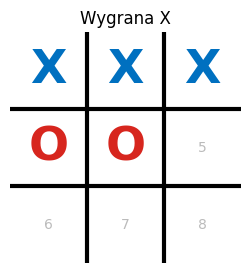

Zwycięzca: X
Koniec gry? True
Wypłata: 1


In [4]:
# Plansza, na której X już wygrał (górny wiersz)
s = z_napisu("XXXOO....")
rysuj(s, tytul="Wygrana X")
print("Zwycięzca:", kk.zwyciezca(s))
print("Koniec gry?", kk.koniec(s))
print("Wypłata:", kk.wyplata(s))

### Eksperyment A — sprawdź, czy rozumiesz funkcje gry

Poniżej są trzy plansze zapisane napisem. **Zanim uruchomisz komórkę**, zapisz dla każdej:
kto rusza, czy gra się skończyła i jaka jest wypłata. Potem uruchom i porównaj.

Następnie wpisz **własną planszę**, na której **O wygrywa po przekątnej**, i sprawdź, czy wypłata wynosi −1.

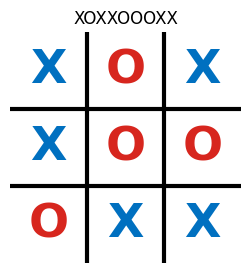

Rusza: MIN  koniec: True  wypłata: 0  ruchy: []


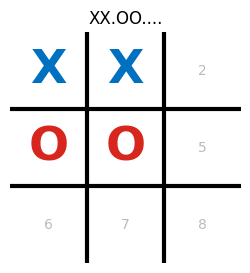

Rusza: MAX  koniec: False  wypłata: 0  ruchy: [2, 5, 6, 7, 8]


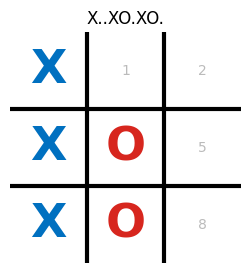

Rusza: MIN  koniec: True  wypłata: 1  ruchy: [1, 2, 5, 8]


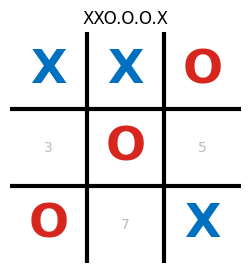

Rusza: MAX  koniec: True  wypłata: -1  ruchy: [3, 5, 7]


In [5]:
plansze = [
    "XOXXOOOXX",     # pełna plansza
    "XX.OO....",     # w trakcie gry
    "X..XO.XO.",     # ?
    "XXO.O.O.X"      # wygrana O po przekątnej
]

for napis in plansze:
    s = z_napisu(napis)
    rysuj(s, tytul=napis)
    print("Rusza:", kk.gracz(s), " koniec:", kk.koniec(s), " wypłata:", kk.wyplata(s), " ruchy:", kk.akcje(s))

## 1.3. Rozgrywka

**Gracz to funkcja**, która dostaje grę i planszę, a zwraca numer pola.
Najprostszy gracz wybiera losowo spośród możliwych ruchów.

Funkcja `rozegraj` robi w pętli trzy rzeczy, dopóki gra się nie skończy:
1. sprawdza, kto rusza,
2. pyta tego gracza o ruch,
3. wykonuje ruch.

Na razie **nie ma tu żadnej sztucznej inteligencji**: są tylko zasady i gracze grający losowo.
W sekcji 2 napiszemy gracza, który „myśli” — będzie to po prostu inna funkcja tego samego typu.

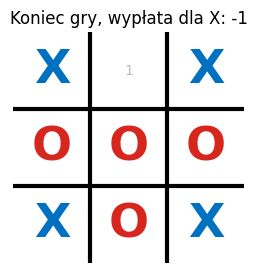

-1

In [6]:
def gracz_losowy(gra, s):
    return random.choice(gra.akcje(s))


def rozegraj(gra, gracz_max, gracz_min, pokaz=True):
    s = gra.start
    while not gra.koniec(s):
        if gra.gracz(s) == "MAX":
            ruch = gracz_max(gra, s)
        else:
            ruch = gracz_min(gra, s)
        s = gra.wynik(s, ruch)
    if pokaz:
        rysuj(s, tytul=f"Koniec gry, wypłata dla X: {gra.wyplata(s)}")
    return gra.wyplata(s)


rozegraj(kk, gracz_losowy, gracz_losowy)

### Ważne: algorytm zna grę tylko przez te sześć funkcji

`rozegraj` nie wie nic o krzyżykach, kółkach ani planszy 3 × 3. Korzysta tylko z `start`, `gracz`, `akcje`,
`wynik` i `koniec`. Tak samo będzie z algorytmami z sekcji 2 i 3.
Dzięki temu wystarczy napisać te same funkcje dla innej gry (np. **cztery w rzędzie** na kolejnych zajęciach),
a te same algorytmy zagrają w nią bez zmiany ani jednej linii.

To ta sama idea co w laboratorium 1: A* dostawał funkcję `neighbors_fn` i działał i dla siatki, i dla 8-puzzle.

## Zadanie 1 — 1000 losowych partii

Rozegraj 1000 partii `gracz_losowy` przeciw `gracz_losowy` (użyj `pokaz=False`, żeby nie rysować plansz)
i policz, ile razy wygrał X, ile razy O, a ile było remisów.

Czy wynik jest symetryczny? Jak myślisz, dlaczego?

In [7]:
wygrane_x = 0
wygrane_o = 0
remisy = 0

for _ in range(1000):
    wynik = rozegraj(kk, gracz_losowy, gracz_losowy, pokaz=False)
    if wynik == 1:
        wygrane_x += 1
    elif wynik == -1:
        wygrane_o += 1
    else:
        remisy += 1

print("X:", wygrane_x, " O:", wygrane_o, " remisy:", remisy)

X: 559  O: 299  remisy: 142


### Pytania do sekcji 1

1. Funkcja `gracz(s)` nie korzysta z żadnej zmiennej „czyj ruch”. Skąd wie, kto rusza? Sprawdź ją na kilku planszach.
2. Ile możliwych ruchów jest na pustej planszy, a ile po trzech ruchach?
3. Czym wypłata różni się od kosztu drogi z laboratorium 1? W którym momencie gry ją znamy?

# 2. Minimax

## 2.1. Pomysł

Chcemy wybrać najlepszy ruch. Naturalny pomysł: **spróbuj każdego ruchu i zobacz, co się stanie**.
Kłopot w tym, że to, co się stanie, zależy od przeciwnika.

Minimax zakłada najgorszy scenariusz: **przeciwnik zawsze wybierze to, co dla nas najgorsze**.
A ponieważ przeciwnik myśli tak samo, musimy przewidzieć też jego przewidywania — i tak aż do końca gry.

Komputer robi to tak jak szachista, który przesuwa figury w głowie: *„gdybym tu, a on tam, a ja wtedy…”*,
a potem wraca do prawdziwej pozycji i sprawdza inny ruch.
**Dlatego `wynik(s, a)` tworzy nową planszę** — stara pozycja musi zostać nietknięta, żeby było do czego wrócić.

## Zadanie 2 — minimax ręcznie

Rusza **X**, zostały trzy wolne pola: 3, 7 i 8.

```text
X | O | X
. | O | O
X | . | .
```

Uzupełnij drzewo (na kartce albo w tej komórce: kliknij dwa razy, żeby edytować).
Pamiętaj: wynik zawsze z punktu widzenia X (+1 wygrana X, 0 remis, −1 wygrana O).

```text
X gra 3  →  X wygrywa od razu (kolumna 0-3-6)                 wartość: +1
X gra 7  →  O wybiera:
               O gra 3 → O wygrywa (wiersz 3-4-5)             wartość: -1
               O gra 8 → O wygrywa (kolumna 2-5-8)            wartość: -1
            O wybierze to, co najgorsze dla X                 wartość: -1
X gra 8  →  O wybiera:
               O gra 3 → O wygrywa (wiersz 3-4-5)             wartość: -1
               O gra 7 → O wygrywa (kolumna 1-4-7)            wartość: -1
            O wybierze to, co najgorsze dla X                 wartość: -1

X wybiera to, co najlepsze dla siebie (największa)    → najlepszy ruch: 3
```

Który ruch X **wygląda rozsądnie, a przegrywa**? Dlaczego?

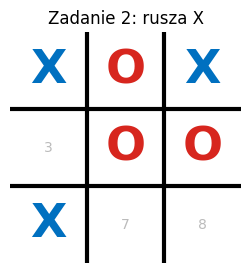

In [8]:
przyklad = z_napisu("XOX.OOX..")
rysuj(przyklad, tytul="Zadanie 2: rusza X")

## 2.2. Reguła

To, co zrobiliśmy ręcznie, da się zapisać w trzech zdaniach:

- **koniec gry** → wartość = wypłata,
- **rusza MAX (X)** → wartość = **największa** z wartości możliwych ruchów,
- **rusza MIN (O)** → wartość = **najmniejsza** z wartości możliwych ruchów.

Wartości liczymy **od końca gry w górę**. Stąd nazwa: mini-max.

Poniższa funkcja robi dokładnie to samo co Ty w zadaniu 2, ale **wypisuje każdy krok**.
Wcięcie pokazuje, jak głęboko w „wyobrażonej” partii jesteśmy.
Uruchom ją i porównaj ze swoim drzewem.
(Używaj jej tylko dla pozycji z kilkoma wolnymi polami — dla pustej planszy wypisałaby setki tysięcy linii.)

In [9]:
def minimax_pokaz(gra, s, wciecie=0):
    odstep = "    " * wciecie
    if gra.koniec(s):
        print(odstep + "koniec gry:", ''.join(s), "→ wypłata", gra.wyplata(s))
        return gra.wyplata(s)
    wartosci = []
    for a in gra.akcje(s):
        znak = 'X' if gra.gracz(s) == "MAX" else 'O'
        print(odstep + f"{znak} gra {a}:")
        wartosci.append(minimax_pokaz(gra, gra.wynik(s, a), wciecie + 1))
    if gra.gracz(s) == "MAX":
        wartosc = max(wartosci)
        print(odstep + f"X wybiera max{wartosci} = {wartosc}")
    else:
        wartosc = min(wartosci)
        print(odstep + f"O wybiera min{wartosci} = {wartosc}")
    return wartosc


minimax_pokaz(kk, przyklad)

X gra 3:
    koniec gry: XOXXOOX.. → wypłata 1
X gra 7:
    O gra 3:
        koniec gry: XOXOOOXX. → wypłata -1
    O gra 8:
        X gra 3:
            koniec gry: XOXXOOXXO → wypłata 1
        X wybiera max[1] = 1
    O wybiera min[-1, 1] = -1
X gra 8:
    O gra 3:
        koniec gry: XOXOOOX.X → wypłata -1
    O gra 7:
        koniec gry: XOX.OOXOX → wypłata -1
    O wybiera min[-1, -1] = -1
X wybiera max[1, -1, -1] = 1


1

## 2.3. Minimax w kodzie

Bez wypisywania funkcja jest bardzo krótka. Kluczowy jest wiersz `minimax(gra, nowy)`:
funkcja **wywołuje samą siebie** dla planszy po ruchu. To jest **rekurencja**.

Można o tym myśleć jak o kierowniku, który nie zna odpowiedzi, więc pyta podwładnych,
a ci pytają swoich podwładnych. Na samym dole ktoś widzi koniec gry i po prostu odczytuje wynik.
Odpowiedzi wracają w górę, a na każdym poziomie ktoś wybiera max albo min.

Zmienna `licznik` **nie wpływa na wynik** — liczy tylko, ile razy funkcja została wywołana
(ile plansz algorytm obejrzał). Słowo `global` pozwala funkcji zmieniać zmienną zdefiniowaną poza nią.

In [10]:
licznik = 0


def minimax(gra, s):
    global licznik
    licznik += 1                              # obejrzeliśmy kolejną planszę

    if gra.koniec(s):                         # koniec gry: znamy wynik
        return gra.wyplata(s)

    wartosci = []
    for a in gra.akcje(s):                    # dla każdego możliwego ruchu:
        nowy = gra.wynik(s, a)                #   plansza po ruchu
        wartosci.append(minimax(gra, nowy))   #   ile jest warta?

    if gra.gracz(s) == "MAX":
        return max(wartosci)
    else:
        return min(wartosci)


licznik = 0
print("Wartość pozycji z zadania 2:", minimax(kk, przyklad))
print("Obejrzane plansze:", licznik)

Wartość pozycji z zadania 2: 1
Obejrzane plansze: 9


### Cała gra od pustej planszy

Teraz to samo dla pustej planszy: minimax sprawdzi **wszystkie możliwe partie kółka i krzyżyka**.

In [11]:
licznik = 0
t0 = time.time()
v = minimax(kk, kk.start)
print("Wartość pustej planszy:", v)
print("Obejrzane plansze:", licznik)          # oczekiwane: 549946
print(f"Czas: {time.time() - t0:.1f} s")

Wartość pustej planszy: 0
Obejrzane plansze: 549946
Czas: 1.5 s


Wartość **0** oznacza remis: **przy idealnej grze obu stron kółko i krzyżyk zawsze kończy się remisem**.
Żeby to stwierdzić, algorytm obejrzał ponad pół miliona plansz.

### Eksperyment B — jak duże jest drzewo?

Zmień `pierwszy_ruch` (pole, na które X stawia pierwszy znak) i uruchom komórkę kilka razy:
dla środka (4), rogu (np. 0) i boku (np. 1).

1. Ile plansz ogląda minimax po jednym ruchu, a ile dla pustej planszy (549 946)? Ile razy mniej?
2. Czy wartość zmienia się w zależności od pierwszego ruchu? Co to oznacza?

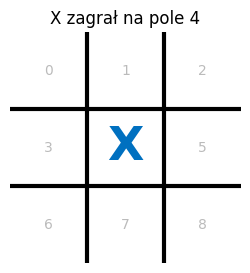

Wartość: 0   obejrzane plansze: 55505


In [12]:
pierwszy_ruch = 4          # ZMIEŃ: 4 (środek), 0 (róg), 1 (bok)

s = kk.wynik(kk.start, pierwszy_ruch)
licznik = 0
v = minimax(kk, s)
rysuj(s, tytul=f"X zagrał na pole {pierwszy_ruch}")
print("Wartość:", v, "  obejrzane plansze:", licznik)

## 2.4. Od wartości do ruchu

Minimax zwraca **liczbę**, a nie ruch. Żeby wybrać ruch:
1. dla każdego możliwego ruchu liczymy wartość planszy po tym ruchu (`wartosci_ruchow`),
2. X wybiera ruch o **największej** wartości, O o **najmniejszej** (`najlepszy_ruch`).

Jeśli kilka ruchów ma tę samą wartość, losujemy jeden z nich, żeby partie były różne.

Parametr `ocen` mówi, którą funkcją liczyć wartości. Na razie to `minimax`;
w sekcji 3 podstawimy tu alfa-beta.

In [13]:
def wartosci_ruchow(gra, s, ocen=minimax):
    wartosci = {}
    for a in gra.akcje(s):
        wartosci[a] = ocen(gra, gra.wynik(s, a))
    return wartosci                           # słownik: ruch -> wartość


def najlepszy_ruch(gra, s, ocen=minimax):
    wartosci = wartosci_ruchow(gra, s, ocen)
    if gra.gracz(s) == "MAX":
        cel = max(wartosci.values())
    else:
        cel = min(wartosci.values())
    najlepsze = [a for a in wartosci if wartosci[a] == cel]
    return random.choice(najlepsze)


print("Wartości ruchów w zadaniu 2:", wartosci_ruchow(kk, przyklad))
print("Najlepszy ruch:", najlepszy_ruch(kk, przyklad))

Wartości ruchów w zadaniu 2: {3: 1, 7: -1, 8: -1}
Najlepszy ruch: 3


### Pozycja-pułapka

X zajął dwa przeciwległe rogi, O stoi w środku. **Rusza O.** Gdzie postawiłbyś O?
Zastanów się, **zanim** uruchomisz komórkę.

Liczby na planszy to wartości ruchów **z punktu widzenia X**. Rusza O, więc O szuka **najmniejszej** liczby.

Rusza: MIN
Wartości ruchów: {1: 0, 2: 1, 3: 0, 5: 0, 6: 1, 7: 0}


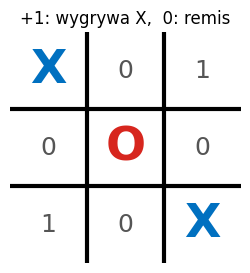

In [14]:
pulapka = z_napisu("X...O...X")
w = wartosci_ruchow(kk, pulapka)
print("Rusza:", kk.gracz(pulapka))
print("Wartości ruchów:", w)
rysuj(pulapka, liczby=w, tytul="+1: wygrywa X,  0: remis")

Ruch w róg wygląda dobrze, ale **przegrywa**: X stawia trzeci róg i ma **dwie groźby naraz**,
a O może zablokować tylko jedną. Ruch na bok zmusza X do obrony i prowadzi do remisu.

Minimax nie ma intuicji i nie zgaduje — **sprawdza wszystko do końca**, dlatego nie daje się nabrać.

### Eksperyment C — przewidź, zanim policzysz

Rusza **O**. Wolne pola: 2, 5, 6, 7.

```text
X | O | .
X | O | .
. | . | X
```

**Zanim uruchomisz komórkę**, zapisz wartość każdego ruchu O (+1, 0 albo −1). Wskazówka: kto ma jakie groźby?
Potem uruchom i porównaj. Jeśli coś się nie zgadza, uruchom `minimax_pokaz(kk, d)` i znajdź, gdzie się pomyliłeś.

Ciekawy jest ruch 6: blokuje groźbę X (kolumna 0-3-6). Dlaczego ma tę samą wartość co natychmiastowa wygrana na polu 7?

Rusza: MIN
Wartości ruchów: {2: 1, 5: 1, 6: -1, 7: -1}


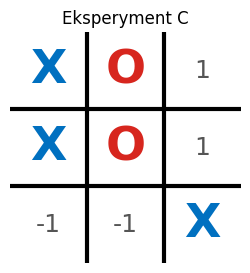

In [15]:
d = z_napisu("XO.XO...X")
w = wartosci_ruchow(kk, d)
print("Rusza:", kk.gracz(d))
print("Wartości ruchów:", w)
rysuj(d, liczby=w, tytul="Eksperyment C")

# minimax_pokaz(kk, d)       # odkomentuj, żeby zobaczyć całe drzewo

## 2.5. Gracz minimax

Gracz minimax to po prostu funkcja tego samego typu co `gracz_losowy`: dostaje planszę i zwraca ruch.
Zagrajmy nim przeciw graczowi losowemu (pierwszy ruch trwa chwilę — to te pół miliona plansz).

In [16]:
def gracz_minimax(gra, s):
    return najlepszy_ruch(gra, s)


wyniki = []
for i in range(5):
    wyniki.append(rozegraj(kk, gracz_minimax, gracz_losowy, pokaz=False))
print("Wypłaty w 5 partiach (minimax jako X):", wyniki)

Wypłaty w 5 partiach (minimax jako X): [1, 1, 1, 1, 1]


### Eksperyment D — zamień graczy

Zmieniaj `GRACZ_X` i `GRACZ_O` i uruchamiaj komórkę. Sprawdź co najmniej trzy ustawienia:

| X | O | czego się spodziewasz? | co wyszło? |
|---|---|---|---|
| `gracz_minimax` | `gracz_losowy` | | |
| `gracz_losowy` | `gracz_minimax` | | |
| `gracz_minimax` | `gracz_minimax` | | |

1. Czy minimax grający jako O wygrywa z losowym tak samo często jak grający jako X? Dlaczego?
2. Co wychodzi, gdy minimax gra sam ze sobą? Jak to się ma do wartości pustej planszy?

In [17]:
GRACZ_X = gracz_minimax      # ZMIEŃ
GRACZ_O = gracz_losowy       # ZMIEŃ
PARTIE = 10

wyniki = [rozegraj(kk, GRACZ_X, GRACZ_O, pokaz=False) for i in range(PARTIE)]
print("Wypłaty:", wyniki)
print("wygrane X:", wyniki.count(1), " remisy:", wyniki.count(0), " wygrane O:", wyniki.count(-1))

Wypłaty: [1, 0, 1, 1, 1, 1, 1, 1, 1, 1]
wygrane X: 9  remisy: 1  wygrane O: 0


### Zagraj z komputerem

Ustaw `GRAJ = True` i uruchom komórkę. Grasz jako X, wpisujesz numer pola (0–8). Spróbuj wygrać.

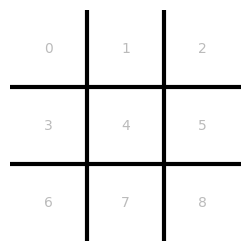

Twój ruch [0, 1, 2, 3, 4, 5, 6, 7, 8]: 8


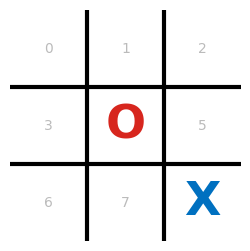

Twój ruch [0, 1, 2, 3, 5, 6, 7]: 5


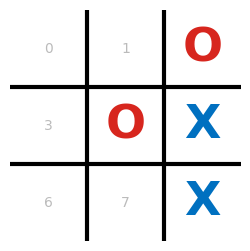

Twój ruch [0, 1, 3, 6, 7]: 6


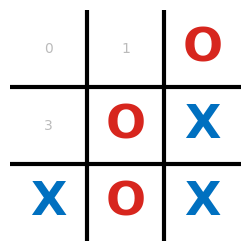

Twój ruch [0, 1, 3]: 1


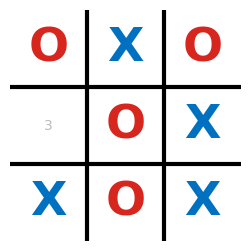

Twój ruch [3]: 3


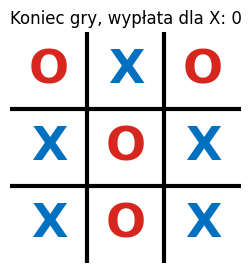

In [19]:
GRAJ = True


def gracz_czlowiek(gra, s):
    rysuj(s)
    while True:
        try:
            a = int(input(f"Twój ruch {gra.akcje(s)}: "))
            if a in gra.akcje(s):
                return a
        except ValueError:
            pass
        print("Niepoprawny ruch.")


if GRAJ:
    rozegraj(kk, gracz_czlowiek, gracz_minimax)

### Pytania do sekcji 2


1. Dlaczego minimax jako X nigdy nie przegra w kółko i krzyżyk? Co mówi o tym wartość pustej planszy?
2. Czy minimax **zawsze** wygra z graczem losowym? Uruchom poprzednią komórkę kilka razy.
3. *(Trudniejsze)* Minimax zakłada, że przeciwnik gra idealnie. Czy to najlepsze założenie przeciw graczowi losowemu?
   Pomyśl o pozycji, w której dwa ruchy mają wartość 0, ale po jednym z nich przeciwnik ma dużo więcej okazji do błędu.

# 3. Cięcia alfa-beta

## 3.1. Pomysł na znanym przykładzie

Wróćmy do pozycji z zadania 2. Minimax obejrzał tam **9 plansz**. Ale spójrz, co X wie w trakcie liczenia:

```text
X gra 3  → +1                      X ma już zapewnione +1
X gra 7  → O gra 3 → −1            O może zrobić −1 (albo coś jeszcze gorszego dla X)
           O gra 8 → ???           czy warto to sprawdzać?
```

Po pierwszej odpowiedzi O wiemy, że ruch 7 jest dla X wart **co najwyżej −1**.
X ma już w kieszeni +1 z ruchu 3, więc ruchu 7 i tak nie wybierze.
**Nie trzeba sprawdzać, co by było po „O gra 8”** — to niczego nie zmieni.

> Jeśli wiem, że ruch jest gorszy, nie muszę wiedzieć, **o ile** gorszy.

## 3.2. α i β

Żeby wiedzieć, kiedy przerwać, algorytm niesie ze sobą dwie liczby:

- **α (alfa)** — najlepsza wartość, jaką **X ma już zapewnioną** (w przykładzie po ruchu 3: α = +1),
- **β (beta)** — najlepsza wartość, jaką **O ma już zapewnioną**.

Na początku nic nie jest zapewnione: α = −∞, β = +∞.

**Cięcie** — przerywamy sprawdzanie dalszych ruchów w węźle, gdy:
- rusza O i znaleźliśmy wartość **≤ α** (X ma gdzie indziej coś lepszego, więc tu nie przyjdzie),
- rusza X i znaleźliśmy wartość **≥ β** (O ma gdzie indziej coś lepszego, więc tu nie pozwoli dojść).

Poniższa funkcja liczy alfa-beta i **wypisuje każdy krok oraz każde cięcie**. Porównaj z wydrukiem `minimax_pokaz`.

In [20]:
def alfabeta_pokaz(gra, s, alfa=-math.inf, beta=math.inf, wciecie=0):
    odstep = "    " * wciecie
    if gra.koniec(s):
        print(odstep + "koniec gry:", ''.join(s), "→ wypłata", gra.wyplata(s))
        return gra.wyplata(s)
    akcje = gra.akcje(s)
    if gra.gracz(s) == "MAX":
        v = -math.inf
        for i, a in enumerate(akcje):
            print(odstep + f"X gra {a}:   (α={alfa}, β={beta})")
            v = max(v, alfabeta_pokaz(gra, gra.wynik(s, a), alfa, beta, wciecie + 1))
            if v >= beta:
                print(odstep + f"CIĘCIE: {v} ≥ β={beta}, pomijam ruchy {akcje[i + 1:]}")
                return v
            alfa = max(alfa, v)
        print(odstep + f"X: wartość {v}")
        return v
    else:
        v = math.inf
        for i, a in enumerate(akcje):
            print(odstep + f"O gra {a}:   (α={alfa}, β={beta})")
            v = min(v, alfabeta_pokaz(gra, gra.wynik(s, a), alfa, beta, wciecie + 1))
            if v <= alfa:
                print(odstep + f"CIĘCIE: {v} ≤ α={alfa}, pomijam ruchy {akcje[i + 1:]}")
                return v
            beta = min(beta, v)
        print(odstep + f"O: wartość {v}")
        return v


alfabeta_pokaz(kk, przyklad)

X gra 3:   (α=-inf, β=inf)
    koniec gry: XOXXOOX.. → wypłata 1
X gra 7:   (α=1, β=inf)
    O gra 3:   (α=1, β=inf)
        koniec gry: XOXOOOXX. → wypłata -1
    CIĘCIE: -1 ≤ α=1, pomijam ruchy [8]
X gra 8:   (α=1, β=inf)
    O gra 3:   (α=1, β=inf)
        koniec gry: XOXOOOX.X → wypłata -1
    CIĘCIE: -1 ≤ α=1, pomijam ruchy [7]
X: wartość 1


1

Wynik jest ten sam (+1), ale dwie gałęzie zostały pominięte: **6 plansz zamiast 9**.

## 3.3. Alfa-beta w kodzie

Porównaj z minimaksem. Zamiast zbierać wszystkie wartości do listy, sprawdzamy ruchy **po kolei**
i po każdym pytamy: *czy można już przerwać?*

Do rekurencji przekazujemy `alfa` i `beta`, bo cięcie głęboko w drzewie zależy od tego,
co zostało już zapewnione wyżej.

Parametr `porzadek` pozwala zmienić **kolejność**, w jakiej sprawdzamy ruchy. Domyślnie (`None`)
sprawdzamy je tak, jak zwraca `akcje`: 0, 1, 2, …, 8. Do czego to służy — za chwilę.

In [21]:
def alfabeta(gra, s, alfa=-math.inf, beta=math.inf, porzadek=None):
    global licznik
    licznik += 1

    if gra.koniec(s):
        return gra.wyplata(s)

    akcje = gra.akcje(s)
    if porzadek is not None:
        akcje = porzadek(s, akcje)            # zmień kolejność sprawdzania ruchów

    if gra.gracz(s) == "MAX":                 # rusza X
        v = -math.inf
        for a in akcje:
            v = max(v, alfabeta(gra, gra.wynik(s, a), alfa, beta, porzadek))
            if v >= beta:                     # O ma gdzie indziej coś lepszego
                return v                      #   → CIĘCIE
            alfa = max(alfa, v)               # X ma zapewnione co najmniej v
        return v
    else:                                     # rusza O
        v = math.inf
        for a in akcje:
            v = min(v, alfabeta(gra, gra.wynik(s, a), alfa, beta, porzadek))
            if v <= alfa:                     # X ma gdzie indziej coś lepszego
                return v                      #   → CIĘCIE
            beta = min(beta, v)               # O ma zapewnione co najwyżej v
        return v


licznik = 0
print("Pozycja z zadania 2 — wartość:", alfabeta(kk, przyklad), " plansze:", licznik)

licznik = 0
t0 = time.time()
v = alfabeta(kk, kk.start)
print("Pusta plansza — wartość:", v, " plansze:", licznik)     # oczekiwane: 0 i 18297
print(f"Czas: {time.time() - t0:.2f} s")

Pozycja z zadania 2 — wartość: 1  plansze: 6
Pusta plansza — wartość: 0  plansze: 18297
Czas: 0.06 s


Ta sama wartość (remis), ale **30 razy mniej plansz** niż minimax (549 946).

**Alfa-beta zawsze daje dokładnie ten sam wynik co minimax.** To nie jest przybliżenie:
pomijamy tylko gałęzie, które dowodnie nie mogą zmienić decyzji.

### Eksperyment E — minimax kontra alfa-beta na różnych pozycjach

Zmieniaj `pozycja`: `przyklad` (zadanie 2), `pulapka`, `d` (eksperyment C), `kk.start`.
Dla każdej zapisz liczbę plansz obu algorytmów.

1. Czy wartość jest zawsze taka sama?
2. Gdzie alfa-beta oszczędza najwięcej — na małych czy na dużych drzewach?

In [22]:
pozycja = pulapka           # ZMIEŃ: przyklad, pulapka, d, kk.start

licznik = 0
v1 = minimax(kk, pozycja)
n1 = licznik

licznik = 0
v2 = alfabeta(kk, pozycja)
n2 = licznik

print(f"minimax:   wartość {v1}, plansze {n1}")
print(f"alfa-beta: wartość {v2}, plansze {n2}")
print(f"alfa-beta obejrzała {n1 / n2:.1f} razy mniej plansz")

minimax:   wartość 0, plansze 1053
alfa-beta: wartość 0, plansze 318
alfa-beta obejrzała 3.3 razy mniej plansz


## 3.4. Kolejność ruchów ma znaczenie

W przykładzie X sprawdził ruch 3 **jako pierwszy** — od razu znalazł najlepszy ruch, a α = +1 pozwoliło ciąć dalej.
Co by było, gdyby zaczął od najgorszych ruchów? Funkcja `porzadek_odwrotny` sprawdza ruchy od końca: 8, 7, 3.

In [23]:
def porzadek_odwrotny(s, akcje):
    return list(reversed(akcje))


licznik = 0
alfabeta(kk, przyklad)
print("Kolejność 3, 7, 8 — plansze:", licznik)

licznik = 0
alfabeta(kk, przyklad, porzadek=porzadek_odwrotny)
print("Kolejność 8, 7, 3 — plansze:", licznik)

Kolejność 3, 7, 8 — plansze: 6
Kolejność 8, 7, 3 — plansze: 9


Wynik ten sam, ale plansz więcej. Zasada:
**im wcześniej znajdziemy dobry ruch, tym szybciej rośnie α (albo maleje β) i tym więcej cięć.**

W kółku i krzyżyku dobre ruchy to zwykle **środek**, potem **rogi**, na końcu **boki**:
środek leży na 4 liniach, róg na 3, bok tylko na 2.

## Zadanie 3 — dobra kolejność ruchów

Napisz funkcję `porzadek_srodek_rogi(s, akcje)`. Funkcja dostaje listę wolnych pól `akcje`
i ma zwrócić **te same pola w innej kolejności**:

**najpierw środek (4) → potem rogi (0, 2, 6, 8) → na końcu boki (1, 3, 5, 7)**

Zajętych pól nie ma w `akcje`, więc nie może ich być także w wyniku.

Przykłady:

| `akcje` (wejście) | wynik |
|---|---|
| `[0, 1, 2, 3, 4, 5, 6, 7, 8]` (pusta plansza) | `[4, 0, 2, 6, 8, 1, 3, 5, 7]` |
| `[1, 2, 3, 5, 6, 7, 8]` (zajęte pola 0 i 4) | `[2, 6, 8, 1, 3, 5, 7]` |

Podpowiedź: przejdź pętlą po liście `[4, 0, 2, 6, 8, 1, 3, 5, 7]` i zostaw tylko te pola, które są w `akcje`.

Parametr `s` (plansza) nie jest tu potrzebny, ale musi być w nagłówku, bo `alfabeta` wywołuje funkcję jako `porzadek(s, akcje)`.

Jeśli wszystko jest dobrze, alfa-beta obejrzy **7 275** plansz.

In [24]:
def porzadek_srodek_rogi(s, akcje):
    kolejnosc = [4, 0, 2, 6, 8, 1, 3, 5, 7]
    return [a for a in kolejnosc if a in akcje]


licznik = 0
v = alfabeta(kk, kk.start, porzadek=porzadek_srodek_rogi)
print("Wartość:", v, " plansze:", licznik)      # oczekiwane: 0 i 7275

Wartość: 0  plansze: 7275


### Porównanie

In [25]:
print(f"{'Algorytm':<34} {'Wartość':<8} {'Plansze':>9}")
print("-" * 53)

licznik = 0
v = minimax(kk, kk.start)
print(f"{'Minimax':<34} {v:<8} {licznik:>9}")

licznik = 0
v = alfabeta(kk, kk.start)
print(f"{'Alfa-beta, kolejność 0-8':<34} {v:<8} {licznik:>9}")

licznik = 0
v = alfabeta(kk, kk.start, porzadek=porzadek_srodek_rogi)
print(f"{'Alfa-beta, środek-rogi-boki':<34} {v:<8} {licznik:>9}")

Algorytm                           Wartość    Plansze
-----------------------------------------------------
Minimax                            0           549946
Alfa-beta, kolejność 0-8           0            18297
Alfa-beta, środek-rogi-boki        0             7275


### Eksperyment F — najgorsza kolejność

Funkcja `porzadek_boki_najpierw` sprawdza ruchy w kolejności **odwrotnej** do zadania 3: najpierw boki, potem rogi, na końcu środek.
Uruchom komórkę. Potem uruchom kilka razy porządek losowy.

Uzupełnij tabelę i odpowiedz: dlaczego najgorsza kolejność daje tyle plansz, skoro wynik jest ten sam?

| kolejność | plansze |
|---|---|
| środek → rogi → boki (zadanie 3) | |
| 0, 1, 2, …, 8 | |
| losowa (kilka prób) | |
| boki → rogi → środek | |

In [26]:
def porzadek_boki_najpierw(s, akcje):
    kolejnosc = [1, 3, 5, 7, 0, 2, 6, 8, 4]
    return [a for a in kolejnosc if a in akcje]


def porzadek_losowy(s, akcje):
    return random.sample(akcje, len(akcje))


licznik = 0
v = alfabeta(kk, kk.start, porzadek=porzadek_boki_najpierw)
print("Boki → rogi → środek:  wartość", v, " plansze:", licznik)

licznik = 0
v = alfabeta(kk, kk.start, porzadek=porzadek_losowy)
print("Losowa kolejność:      wartość", v, " plansze:", licznik)

Boki → rogi → środek:  wartość 0  plansze: 42094
Losowa kolejność:      wartość 0  plansze: 11999


### Pytania do sekcji 3

1. Dlaczego alfa-beta daje **zawsze ten sam wynik** co minimax?
2. Dlaczego kolejność ruchów zmienia liczbę plansz, ale nie zmienia wyniku?
3. W kółku i krzyżyku wiemy, że środek jest dobry. Skąd wziąć „dobrą kolejność” w grze, której nie znamy tak dobrze?

# 4. Podsumowanie

**Gra jako dane.** Grę opisujemy sześcioma funkcjami: `start`, `gracz`, `akcje`, `wynik`, `koniec`, `wyplata`.
Algorytmy znają grę tylko przez nie, więc działają dla każdej gry.

**Minimax.** X wybiera maksimum, O minimum, wartości liczymy od końca gry w górę.
Wynik jest optymalny (przeciw idealnemu przeciwnikowi), ale trzeba obejrzeć całe drzewo.

**Alfa-beta.** Ten sam wynik co minimax, ale bez gałęzi, które nie mogą zmienić decyzji.
Najwięcej cięć, gdy najpierw sprawdzamy najlepsze ruchy.

